# 🧪 Étape 3 : Tests d'audit sur 100 % des écritures

**Objectif :** transformer les signaux repérés à l'exploration en **tests systématiques**, appliqués à toutes les écritures. C'est ce que les auditeurs appellent le **journal entry testing**.

Pourquoi c'est important : la norme d'audit **ISA 240** (NEP 240 en France) impose à l'auditeur de tester les écritures comptables pour détecter un éventuel **contournement des contrôles par la direction**. Avec la data, on ne teste plus un échantillon : on teste **tout**.

Plan :
1. Préparer un tableau « une ligne par écriture »
2. Appliquer 8 tests, un par un, en expliquant la logique d'audit de chacun
3. Prioriser : quelles écritures cumulent plusieurs alertes ?
4. Évaluer : on ouvre enfin la « correction » pour mesurer la performance des tests
5. Prendre du recul sur les limites de l'approche

> Le code des tests est dans [`src/tests_audit.py`](../src/tests_audit.py) : chaque test est une petite fonction documentée, réutilisable sur un vrai FEC.

## 1. Préparation

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(RACINE / "src"))
from chargement import charger_fec
import tests_audit as ta

FIGURES = RACINE / "reports" / "figures"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 100})
pd.options.display.float_format = lambda x: f"{x:,.2f}".replace(",", " ")
pd.options.display.max_colwidth = 60

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png", dpi=120, bbox_inches="tight")

fec = charger_fec()

Le FEC contient une ligne par **mouvement**. Or les tests portent sur des **écritures** (une facture, un règlement…). On regroupe donc les lignes par `EcritureNum`, en calculant pour chaque écriture : son montant, son solde (débit - crédit), son tiers, son délai de validation et son **schéma comptable**, c'est-à-dire la combinaison des comptes mouvementés et de leur sens.

In [2]:
ecr = ta.tableau_ecritures(fec)
print(f"{len(ecr):,} écritures".replace(",", " "))
ecr.head()

6 655 écritures


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,montant,solde,nb_lignes,tiers,tiers_lib,schema,delai_validation
EcritureNum,,,,,,,,,,,,
AC000001,AC,2025-01-02,2025-01-05,F0015-72310,Facture F0015-72310 Comptoir Métal Design,20 816.54,0.00,3,F0015,Comptoir Métal Design,401000C 445660D 607000D,3
AC000002,AC,2025-01-02,2025-01-07,F0012-25528,Facture F0012-25528 Import Verre & Laiton,949.70,-0.00,3,F0012,Import Verre & Laiton,401000C 445660D 607000D,5
AC000003,AC,2025-01-02,2025-01-05,F0018-55793,Facture F0018-55793 Comptoir Éclat,5 330.23,0.00,3,F0018,Comptoir Éclat,401000C 445660D 607000D,3
AC000004,AC,2025-01-02,2025-01-03,LOYER-2025-01,Facture LOYER-2025-01 SCI Les Tilleuls,4 200.00,0.00,3,F0022,SCI Les Tilleuls,401000C 445660D 613200D,1
AC000005,AC,2025-01-03,2025-01-06,F0001-18454,Facture F0001-18454 Fabrique Atlas,2 124.79,0.00,3,F0001,Fabrique Atlas,401000C 445660D 607000D,3


In [3]:
# Les schémas comptables les plus fréquents : ils décrivent le fonctionnement « normal » de l'entreprise
ecr["schema"].value_counts().head(8).to_frame("écritures")

,écritures
schema,
411000D 445710C 707000C,2410
411000C 512000D,1909
401000D 512000C,1031
401000C 445660D 607000D,912
401000C 445660D 606100D,150
401000C 445660D 625100D,100
401000C 445660D 622600D,18
401000C 445660D 613200D,12


On reconnaît les opérations courantes : `411000D 445710C 707000C` est une facture de vente (client au débit, TVA collectée et vente au crédit), `401000C 445660D 607000D` un achat de marchandises, `411000C 512000D` un encaissement client…

## 2. Les 8 tests d'audit

### 2.1 Écritures déséquilibrées

En comptabilité en partie double, chaque écriture doit avoir **débit = crédit**. Une écriture déséquilibrée révèle une erreur de saisie, mais aussi un **défaut du logiciel**, qui n'aurait jamais dû permettre de la valider.

In [4]:
alertes = ta.test_desequilibre(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant", "solde"]].head(10)

Écritures signalées : 4


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant,solde
EcritureNum,,,,,,,,
OD000004,OD,2025-03-10,2025-03-15,OD-8016,Reclassement de charges,,5 886.00,-9.00
OD000008,OD,2025-05-26,2025-05-31,OD-4701,Reclassement de charges,,2 468.00,-180.00
OD000012,OD,2025-10-07,2025-10-10,OD-6544,Reclassement de charges,,9 413.00,270.00
OD000014,OD,2025-11-12,2025-11-15,OD-6995,Reclassement de charges,,3 815.00,630.00


### 2.2 Saisies le week-end ou un jour férié

Une écriture passée hors des jours ouvrés échappe souvent aux contrôles habituels (validation hiérarchique, séparation des tâches). C'est un test classique de contournement des contrôles.

In [5]:
alertes = ta.test_jour_non_ouvre(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].head(10)

Écritures signalées : 15


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant
EcritureNum,,,,,,,
AC000434,AC,2025-05-03,2025-05-03,F0016-91730,Facture F0016-91730 Grossiste Nordlicht,Grossiste Nordlicht,297.47
AC000820,AC,2025-09-07,2025-09-09,F0025-68930,Facture F0025-68930 Hôtels Étape Business,Hôtels Étape Business,402.26
AC000935,AC,2025-10-12,2025-10-12,F0024-45687,Facture F0024-45687 Voyages Affaires Express,Voyages Affaires Express,573.14
AC001057,AC,2025-11-15,2025-11-19,F0017-93016,Facture F0017-93016 Fabrique Éclat,Fabrique Éclat,599.51
AC001058,AC,2025-11-15,2025-11-16,TEL-2025-11,Facture TEL-2025-11 TéléCom Pro Services,TéléCom Pro Services,204.25
VE000526,VE,2025-03-30,2025-04-03,FA2025-00509,Facture FA2025-00509 Restaurant Confluence,Restaurant Confluence,1 746.40
VE000575,VE,2025-04-06,2025-04-10,FA2025-00529,Facture FA2025-00529 Restaurant Opale,Restaurant Opale,121.38
VE000680,VE,2025-04-19,2025-04-19,FA2025-00639,Facture FA2025-00639 Agence Confluence,Agence Confluence,1 086.55
VE001120,VE,2025-06-29,2025-07-03,FA2025-01095,Facture FA2025-01095 Boutique Montmartre,Boutique Montmartre,639.25


### 2.3 Montants ronds

Les vraies factures ont rarement des montants parfaitement ronds (TVA, quantités, prix unitaires…). Un montant rond, comme 5 000 € ou 10 000 €, évoque plutôt une **estimation**, un ajustement manuel ou un montant inventé. On retient les montants d'au moins 1 000 € multiples de 500 €.

In [6]:
alertes = ta.test_montant_rond(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].head(10)

Écritures signalées : 14


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant
EcritureNum,,,,,,,
OD000001,OD,2025-01-06,2025-01-09,OD-7017,Divers,,5 000.00
OD000002,OD,2025-01-20,2025-01-24,OD-2279,Divers,,15 000.00
OD000003,OD,2025-01-23,2025-01-25,OD-9552,Ajustement,,7 500.00
OD000005,OD,2025-03-27,2025-03-28,OD-8621,Frais divers,,1 500.00
OD000006,OD,2025-03-27,2025-03-31,OD-8755,Frais divers,,1 000.00
OD000007,OD,2025-04-23,2025-04-27,OD-7283,Ajustement,,3 000.00
OD000009,OD,2025-06-06,2025-06-06,OD-5125,Ajustement,,15 000.00
OD000010,OD,2025-08-07,2025-08-09,OD-6317,Frais divers,,15 000.00
OD000011,OD,2025-08-19,2025-08-22,OD-9428,Frais divers,,10 000.00


### 2.4 Factures fournisseurs en double

Une même facture (même fournisseur, même numéro de pièce) comptabilisée deux fois signifie souvent qu'elle a été **payée deux fois**. C'est une perte directe pour l'entreprise, et parfois une fraude organisée avec un fournisseur complice.

In [7]:
alertes = ta.test_doublon(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].head(10)

Écritures signalées : 12


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant
EcritureNum,,,,,,,
AC000349,AC,2025-04-07,2025-04-10,F0007-47823,Facture F0007-47823 Distribution Nordlicht,Distribution Nordlicht,1 091.87
AC000355,AC,2025-04-08,2025-04-08,F0008-94784,Facture F0008-94784 Import Nordlicht,Import Nordlicht,379.62
AC000394,AC,2025-04-18,2025-04-19,F0001-85744,Facture F0001-85744 Fabrique Atlas,Fabrique Atlas,517.74
AC000476,AC,2025-05-15,2025-05-16,F0009-47622,Facture F0009-47622 Manufacture Céramique du Sud,Manufacture Céramique du Sud,425.45
AC000502,AC,2025-05-26,2025-05-30,F0015-66459,Facture F0015-66459 Comptoir Métal Design,Comptoir Métal Design,1 311.71
AC000633,AC,2025-07-11,2025-07-16,F0013-11599,Facture F0013-11599 Comptoir Céramique du Sud,Comptoir Céramique du Sud,2 175.83
AC000777,AC,2025-08-25,2025-08-30,F0001-32003,Facture F0001-32003 Fabrique Atlas,Fabrique Atlas,1 389.96
AC000910,AC,2025-10-01,2025-10-05,F0007-63261,Facture F0007-63261 Distribution Nordlicht,Distribution Nordlicht,781.03
AC001007,AC,2025-10-31,2025-11-05,F0004-70198,Facture F0004-70198 Manufacture Lumen,Manufacture Lumen,1 732.78


In [8]:
# Pour chaque doublon, on retrouve la facture d'origine
doublons = ecr.loc[alertes, ["tiers", "PieceRef"]]
ecr[ecr.set_index(["tiers", "PieceRef"]).index.isin(doublons.set_index(["tiers", "PieceRef"]).index)
    & (ecr["JournalCode"] == "AC")].sort_values(["PieceRef", "EcritureDate"])[
    ["EcritureDate", "PieceRef", "tiers_lib", "montant"]].head(8)

,EcritureDate,PieceRef,tiers_lib,montant
EcritureNum,,,,
AC000747,2025-08-18,F0001-32003,Fabrique Atlas,1 389.96
AC000777,2025-08-25,F0001-32003,Fabrique Atlas,1 389.96
AC000364,2025-04-11,F0001-85744,Fabrique Atlas,517.74
AC000394,2025-04-18,F0001-85744,Fabrique Atlas,517.74
AC000966,2025-10-21,F0004-70198,Manufacture Lumen,1 732.78
AC001007,2025-10-31,F0004-70198,Manufacture Lumen,1 732.78
AC001060,2025-11-17,F0006-75909,Fabrique Lumen,3 123.64
AC001096,2025-11-26,F0006-75909,Fabrique Lumen,3 123.64


### 2.5 Écritures importantes en fin d'exercice

Les derniers jours de l'exercice sont la période la plus risquée : c'est là qu'on peut gonfler le chiffre d'affaires ou décaler des charges pour **embellir le résultat** (*cut-off*). On retient les écritures des 5 derniers jours dont le montant dépasse le 95e percentile de leur journal.

In [9]:
alertes = ta.test_fin_exercice(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].head(10)

Écritures signalées : 13


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant
EcritureNum,,,,,,,
AC001197,AC,2025-12-30,2026-01-04,F0004-49643,Facture F0004-49643 Manufacture Lumen,Manufacture Lumen,8 200.69
AC001198,AC,2025-12-30,2025-12-31,F0008-90417,Facture F0008-90417 Import Nordlicht,Import Nordlicht,7 451.05
VE002373,VE,2025-12-29,2026-01-17,FA2025-02373,Facture FA2025-02373 prestation complémentaire Studio du...,Studio du Port,23 760.00
VE002374,VE,2025-12-29,2026-01-22,FA2025-02374,Facture FA2025-02374 prestation complémentaire Boutique ...,Boutique Bellevue,14 280.00
VE002375,VE,2025-12-29,2026-01-16,FA2025-02375,Facture FA2025-02375 prestation complémentaire Boutique ...,Boutique Montmartre,9 720.00
VE002376,VE,2025-12-29,2026-01-26,FA2025-02376,Facture FA2025-02376 prestation complémentaire Hôtel des...,Hôtel des Arts,29 520.00
VE002387,VE,2025-12-30,2026-01-25,FA2025-02387,Facture FA2025-02387 prestation complémentaire Boutique ...,Boutique Montmartre,26 640.00
VE002388,VE,2025-12-30,2026-01-21,FA2025-02388,Facture FA2025-02388 prestation complémentaire Galerie C...,Galerie Confluence,10 320.00
VE002401,VE,2025-12-31,2026-01-03,FA2025-02401,Facture FA2025-02401 Agence Confluence,Agence Confluence,5 903.40


### 2.6 Validations tardives

Une écriture est normalement validée quelques jours après sa date. Une validation **des semaines ou des mois plus tard** peut signaler une écriture **antidatée**, saisie après coup pour modifier les comptes d'une période déjà close.

In [10]:
alertes = ta.test_validation_tardive(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant", "delai_validation"]].head(10)

Écritures signalées : 19


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant,delai_validation
EcritureNum,,,,,,,,
AC000416,AC,2025-04-25,2025-08-30,AV-F0016-517,Avoir commercial Grossiste Nordlicht,Grossiste Nordlicht,1 958.39,127
AC000520,AC,2025-06-02,2025-11-24,AV-F0001-526,Avoir commercial Fabrique Atlas,Fabrique Atlas,3 599.46,175
AC000584,AC,2025-06-27,2025-10-15,AV-F0018-648,Avoir commercial Comptoir Éclat,Comptoir Éclat,3 738.43,110
AC000661,AC,2025-07-24,2026-01-24,AV-F0008-935,Avoir commercial Import Nordlicht,Import Nordlicht,3 625.91,184
AC000736,AC,2025-08-13,2026-01-13,AV-F0017-992,Avoir commercial Fabrique Éclat,Fabrique Éclat,2 661.72,153
AC000742,AC,2025-08-14,2026-02-27,AV-F0009-170,Avoir commercial Manufacture Céramique du Sud,Manufacture Céramique du Sud,1 808.82,197
AC000794,AC,2025-08-28,2025-12-29,AV-F0007-692,Avoir commercial Distribution Nordlicht,Distribution Nordlicht,1 392.30,123
AC000860,AC,2025-09-18,2026-02-11,AV-F0007-694,Avoir commercial Distribution Nordlicht,Distribution Nordlicht,5 471.08,146
OD000017,OD,2025-12-31,2026-01-15,AMORT-2025,Dotation aux amortissements 2025,,12 000.00,15


### 2.7 Factures répétées juste sous le seuil d'approbation

Au-delà de 5 000 € HT, une facture doit être approuvée par un responsable. Un fraudeur peut **fractionner** une grosse dépense en plusieurs factures juste sous ce seuil. On signale les fournisseurs ayant au moins 3 factures entre 4 500 et 5 000 € HT.

In [11]:
alertes = ta.test_sous_seuil(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant"]].head(10)

Écritures signalées : 20


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant
EcritureNum,,,,,,,
AC000035,AC,2025-01-13,2025-01-18,F0008-63372,Facture F0008-63372 Import Nordlicht,Import Nordlicht,5 993.03
AC000417,AC,2025-04-28,2025-05-03,F0006-26090,Facture F0006-26090 Fabrique Lumen,Fabrique Lumen,5 606.62
AC000551,AC,2025-06-13,2025-06-17,F0099-41750,Facture F0099-41750 Conseil Stratégie Plus,Conseil Stratégie Plus,5 766.54
AC000608,AC,2025-07-04,2025-07-06,F0008-14086,Facture F0008-14086 Import Nordlicht,Import Nordlicht,5 955.56
AC000645,AC,2025-07-18,2025-07-23,F0099-54558,Facture F0099-54558 Conseil Stratégie Plus,Conseil Stratégie Plus,5 952.31
AC000646,AC,2025-07-18,2025-07-21,F0099-42459,Facture F0099-42459 Conseil Stratégie Plus,Conseil Stratégie Plus,5 758.24
AC000769,AC,2025-08-22,2025-08-26,F0099-50632,Facture F0099-50632 Conseil Stratégie Plus,Conseil Stratégie Plus,5 876.33
AC000770,AC,2025-08-22,2025-08-22,F0099-78253,Facture F0099-78253 Conseil Stratégie Plus,Conseil Stratégie Plus,5 933.11
AC000844,AC,2025-09-16,2025-09-20,F0008-16762,Facture F0008-16762 Import Nordlicht,Import Nordlicht,5 653.97


### 2.8 Combinaisons de comptes inhabituelles

Chaque type d'opération suit toujours le même schéma comptable. Un schéma utilisé **moins de 10 fois dans l'année** sort de la routine : opération exceptionnelle, erreur d'imputation, ou écriture qui contourne le circuit normal (par exemple un salaire payé directement par la banque, hors paie).

In [12]:
alertes = ta.test_schema_rare(fec, ecr)
print(f"Écritures signalées : {alertes.sum()}")
ecr.loc[alertes, ["JournalCode", "EcritureDate", "ValidDate", "PieceRef", "EcritureLib", "tiers_lib", "montant", "schema"]].head(10)

Écritures signalées : 31


,JournalCode,EcritureDate,ValidDate,PieceRef,EcritureLib,tiers_lib,montant,schema
EcritureNum,,,,,,,,
AC000416,AC,2025-04-25,2025-08-30,AV-F0016-517,Avoir commercial Grossiste Nordlicht,Grossiste Nordlicht,1 958.39,401000D 445660C 607000C
AC000520,AC,2025-06-02,2025-11-24,AV-F0001-526,Avoir commercial Fabrique Atlas,Fabrique Atlas,3 599.46,401000D 445660C 607000C
AC000584,AC,2025-06-27,2025-10-15,AV-F0018-648,Avoir commercial Comptoir Éclat,Comptoir Éclat,3 738.43,401000D 445660C 607000C
AC000661,AC,2025-07-24,2026-01-24,AV-F0008-935,Avoir commercial Import Nordlicht,Import Nordlicht,3 625.91,401000D 445660C 607000C
AC000736,AC,2025-08-13,2026-01-13,AV-F0017-992,Avoir commercial Fabrique Éclat,Fabrique Éclat,2 661.72,401000D 445660C 607000C
AC000742,AC,2025-08-14,2026-02-27,AV-F0009-170,Avoir commercial Manufacture Céramique du Sud,Manufacture Céramique du Sud,1 808.82,401000D 445660C 607000C
AC000794,AC,2025-08-28,2025-12-29,AV-F0007-692,Avoir commercial Distribution Nordlicht,Distribution Nordlicht,1 392.30,401000D 445660C 607000C
AC000860,AC,2025-09-18,2026-02-11,AV-F0007-694,Avoir commercial Distribution Nordlicht,Distribution Nordlicht,5 471.08,401000D 445660C 607000C
BQ000003,BQ,2025-01-10,2025-01-13,VIR-68445,Prime exceptionnelle,,1 314.57,512000C 641000D


In [13]:
# Les schémas rares et leur fréquence
ecr.loc[alertes, "schema"].value_counts().to_frame("écritures")

,écritures
schema,
401000D 445660C 607000C,8
512000C 641000D,6
512000C 622600D,5
512000C 625100D,4
606100D 607000C,4
512000C 606100D,3
281830C 681120D,1


## 3. Synthèse et priorisation

On applique maintenant les 8 tests d'un coup. Chaque écriture reçoit un **nombre d'alertes** : plus il est élevé, plus l'écriture est prioritaire pour l'auditeur.

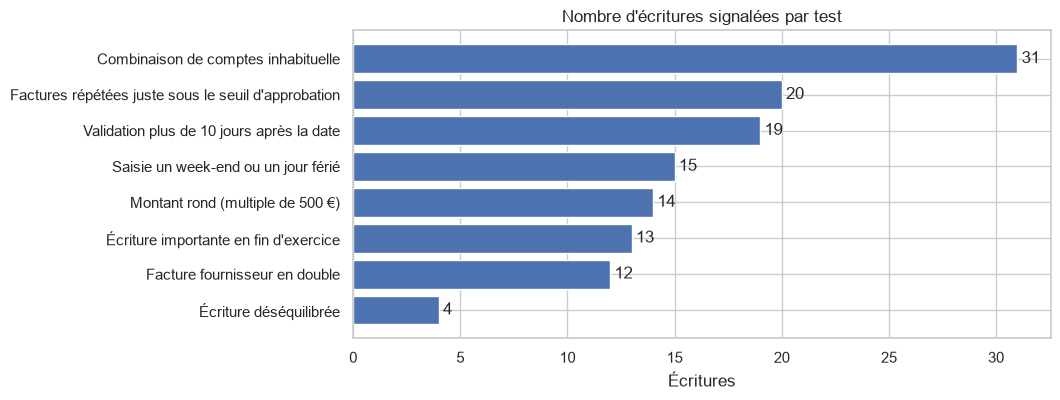

In [14]:
resultats = ta.appliquer_tests(fec)
noms_tests = list(ta.TESTS)
libelles = {nom: lib for nom, (_, lib) in ta.TESTS.items()}

nb_par_test = resultats[noms_tests].sum().rename(libelles).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(nb_par_test.index, nb_par_test.values, color="#4C72B0")
ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Nombre d'écritures signalées par test", xlabel="Écritures")
sauver(fig, "07_alertes_par_test")
plt.show()

In [15]:
repartition = resultats["nb_alertes"].value_counts().sort_index().to_frame("écritures")
repartition.index.name = "nombre d'alertes"
repartition

,écritures
nombre d'alertes,
0,6564
1,56
2,33
3,2


In [16]:
# Les écritures les plus suspectes : celles qui déclenchent plusieurs tests
prioritaires = resultats[resultats["nb_alertes"] >= 2].sort_values("nb_alertes", ascending=False)
prioritaires.assign(tests=prioritaires[noms_tests].apply(lambda l: ", ".join(l.index[l]), axis=1))[
    ["JournalCode", "EcritureDate", "EcritureLib", "tiers_lib", "montant", "nb_alertes", "tests"]].head(15)

,JournalCode,EcritureDate,EcritureLib,tiers_lib,montant,nb_alertes,tests
EcritureNum,,,,,,,
VE002407,VE,2025-12-31,Facture FA2025-02407 prestation complémentaire Boutique ...,Boutique Bellevue,15 000.00,3,"montant_rond, fin_exercice, validation_tardive"
OD000017,OD,2025-12-31,Dotation aux amortissements 2025,,12 000.00,3,"montant_rond, validation_tardive, schema_rare"
AC000416,AC,2025-04-25,Avoir commercial Grossiste Nordlicht,Grossiste Nordlicht,1 958.39,2,"validation_tardive, schema_rare"
AC000584,AC,2025-06-27,Avoir commercial Comptoir Éclat,Comptoir Éclat,3 738.43,2,"validation_tardive, schema_rare"
AC000520,AC,2025-06-02,Avoir commercial Fabrique Atlas,Fabrique Atlas,3 599.46,2,"validation_tardive, schema_rare"
AC000661,AC,2025-07-24,Avoir commercial Import Nordlicht,Import Nordlicht,3 625.91,2,"validation_tardive, schema_rare"
AC000736,AC,2025-08-13,Avoir commercial Fabrique Éclat,Fabrique Éclat,2 661.72,2,"validation_tardive, schema_rare"
AC000860,AC,2025-09-18,Avoir commercial Distribution Nordlicht,Distribution Nordlicht,5 471.08,2,"validation_tardive, schema_rare"
OD000001,OD,2025-01-06,Divers,,5 000.00,2,"montant_rond, schema_rare"


👉 Sur plus de 6 600 écritures, les tests en isolent **moins d'une centaine**. L'auditeur peut concentrer ses vérifications (demander les justificatifs, interroger les personnes concernées) sur cette courte liste, en commençant par les écritures qui cumulent plusieurs alertes.

## 4. Évaluation : combien d'anomalies cachées ont été retrouvées ?

On ouvre enfin la « correction » (`anomalies_injectees.csv`), qui n'a pas servi jusqu'ici. Deux indicateurs :

- **Rappel** : parmi les vraies anomalies, quelle part a été retrouvée ? *(« a-t-on raté des fraudes ? »)*
- **Précision** : parmi les écritures signalées, quelle part est vraiment anormale ? *(« fait-on perdre du temps à l'auditeur avec des fausses alertes ? »)*

In [17]:
anomalies = pd.read_csv(RACINE / "data" / "raw" / "anomalies_injectees.csv")
evaluation = ta.evaluer(resultats, anomalies)
evaluation["global"].to_frame("valeur").style.format(
    lambda v: f"{v:.0%}" if isinstance(v, float) and v <= 1 else f"{v:,.0f}".replace(",", " "))

,valeur
Écritures testées,6 655
Écritures signalées (≥ 1 test),91
Anomalies cachées,81
Anomalies retrouvées,81
Rappel,100%
Précision,89%


In [18]:
evaluation["par_test"].style.format({"précision": "{:.0%}"})

,description,signalées,vraies anomalies,fausses alertes,précision
test,,,,,
desequilibre,Écriture déséquilibrée,4,4,0,100%
jour_non_ouvre,Saisie un week-end ou un jour férié,15,15,0,100%
montant_rond,Montant rond (multiple de 500 €),14,13,1,93%
doublon,Facture fournisseur en double,12,12,0,100%
fin_exercice,Écriture importante en fin d'exercice,13,10,3,77%
validation_tardive,Validation plus de 10 jours après la date,19,18,1,95%
sous_seuil,Factures répétées juste sous le seuil d'approbation,20,14,6,70%
schema_rare,Combinaison de comptes inhabituelle,31,30,1,97%


In [19]:
evaluation["par_type"].style.format({"rappel": "{:.0%}"})

,anomalies,retrouvées,rappel
type,,,
contrepartie_inhabituelle,6,6,100%
desequilibre,4,4,100%
doublon,12,12,100%
fractionnement_seuil,14,14,100%
montant_rond,12,12,100%
saisie_weekend,15,15,100%
validation_tardive,8,8,100%
vente_fictive_cloture,10,10,100%


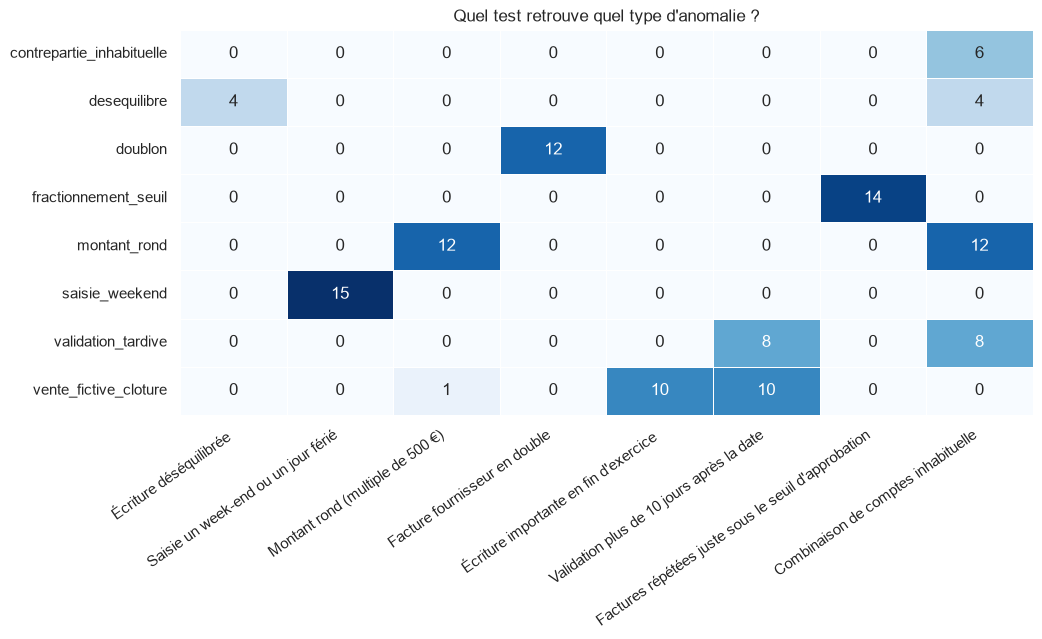

In [20]:
matrice = evaluation["matrice"].rename(columns=libelles)
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set(title="Quel test retrouve quel type d'anomalie ?", xlabel="", ylabel="")
plt.xticks(rotation=35, ha="right")
sauver(fig, "08_matrice_tests_anomalies")
plt.show()

**Lecture de la matrice :** chaque type d'anomalie est retrouvé par au moins un test, et souvent par plusieurs. Par exemple, les avoirs antidatés sont détectés à la fois par la validation tardive **et** par le schéma rare (fournisseur au débit, achats au crédit). Ce **recoupement** renforce la confiance dans l'alerte.

In [21]:
# Les fausses alertes : écritures signalées qui ne sont pas des anomalies
fausses = resultats[(resultats["nb_alertes"] > 0) & ~resultats.index.isin(anomalies["EcritureNum"])]
fausses.assign(tests=fausses[noms_tests].apply(lambda l: ", ".join(l.index[l]), axis=1))[
    ["JournalCode", "EcritureDate", "EcritureLib", "tiers_lib", "montant", "tests"]]

,JournalCode,EcritureDate,EcritureLib,tiers_lib,montant,tests
EcritureNum,,,,,,
AC000035,AC,2025-01-13,Facture F0008-63372 Import Nordlicht,Import Nordlicht,5 993.03,sous_seuil
AC000417,AC,2025-04-28,Facture F0006-26090 Fabrique Lumen,Fabrique Lumen,5 606.62,sous_seuil
AC000608,AC,2025-07-04,Facture F0008-14086 Import Nordlicht,Import Nordlicht,5 955.56,sous_seuil
AC000844,AC,2025-09-16,Facture F0008-16762 Import Nordlicht,Import Nordlicht,5 653.97,sous_seuil
AC000879,AC,2025-09-23,Facture F0006-24111 Fabrique Lumen,Fabrique Lumen,5 879.98,sous_seuil
AC000986,AC,2025-10-27,Facture F0006-57672 Fabrique Lumen,Fabrique Lumen,5 536.86,sous_seuil
AC001197,AC,2025-12-30,Facture F0004-49643 Manufacture Lumen,Manufacture Lumen,8 200.69,fin_exercice
AC001198,AC,2025-12-30,Facture F0008-90417 Import Nordlicht,Import Nordlicht,7 451.05,fin_exercice
OD000017,OD,2025-12-31,Dotation aux amortissements 2025,,12 000.00,"montant_rond, validation_tardive, schema_rare"


Les fausses alertes sont **explicables** : la dotation aux amortissements (un montant rond, validé en janvier, de schéma unique), quelques gros achats et ventes légitimes de fin décembre, ou deux fournisseurs réels ayant plusieurs factures proches de 5 000 €. Un auditeur les écarterait en quelques minutes, au vu des justificatifs.

## 5. Prendre du recul : les limites de cette approche

Les résultats sont excellents : **tout est retrouvé**, avec environ **9 alertes sur 10 justifiées**. Mais il faut être honnête sur ce que cela démontre :

1. **Les tests ont été conçus en connaissant les schémas de fraude** que l'on avait nous-mêmes injectés. Sur un vrai FEC, les fraudes sont plus subtiles et la précision serait nettement plus faible.
2. **Les règles ne détectent que ce qu'on leur demande de chercher.** Un fraudeur qui connaît les contrôles peut les éviter (saisir en semaine, choisir des montants non ronds, rester sous les 90 % du seuil…).
3. **Les seuils sont arbitraires** (5 jours, 95e percentile, 10 jours…). Ils doivent être adaptés à chaque entreprise et justifiés dans le dossier d'audit.

C'est pourquoi la suite du projet utilise des méthodes qui **ne partent pas d'une liste de fraudes connues** :
- **Étape 4, loi de Benford** : détecter des montants « non naturels » sans hypothèse sur la fraude ;
- **Étape 5, machine learning non supervisé** : laisser un algorithme repérer les écritures qui « ne ressemblent pas aux autres ».

## 6. Sauvegarde des résultats

In [22]:
sortie = RACINE / "data" / "processed" / "ecritures_tests.csv"
resultats.to_csv(sortie, encoding="utf-8")
print(f"Résultats sauvegardés : {sortie.relative_to(RACINE)} ({len(resultats):,} écritures)".replace(",", " "))

Résultats sauvegardés : data\processed\ecritures_tests.csv (6 655 écritures)


## ✅ Ce qu'il faut retenir

| | |
|---|---|
| Écritures testées | 100 % (≈ 6 650) |
| Écritures à examiner | < 100, soit environ 1,4 % |
| Anomalies retrouvées | toutes, sur 8 types de fraude ou d'erreur |
| Fausses alertes | environ 1 sur 10, toutes explicables |

**La compétence démontrée :** traduire des risques d'audit en règles de données claires, documentées et paramétrables, puis mesurer leur efficacité avec des indicateurs objectifs (précision, rappel).